# The GT40 at full detail: high-resolution voxels, aerodynamic loads, and Parquet I/O

The [previous GT40 notebook](minecraft_gt40.ipynb) used coarse grids to explore how low the resolution can go before the car stops reading as a car. This one goes the other direction: a 220 × 80 × 50 hexahedral grid (~81 000 voxels) that captures the compound curves of the bodywork with enough fidelity to be useful as a preliminary FEA model.

With a proper mesh in hand, we move beyond geometry:

1. **Concentrated loads** — drag forces computed from basic aerodynamics are distributed as nodal point loads on the front face of the voxel model and stored directly in the mesh's `PointData`.
2. **Parquet round-trip** — the full model (coordinates, topology, and load vector) is saved to two Parquet files and reloaded, demonstrating that nothing is lost in the round-trip.

## Load the surface scan

In [1]:
from sigmaepsilon.mesh.downloads import download_gt40

mesh = download_gt40(read=True)
leaf = mesh[5]
coords_T3 = mesh.coords()
topo_T3 = leaf.cd.topology().to_numpy()

size = coords_T3.max(axis=0) - coords_T3.min(axis=0)
print(f"{coords_T3.shape[0]:,} points, {topo_T3.shape[0]:,} triangles")
print(f"Bounding box (L × W × H mm): {size[0]:.0f} × {size[1]:.0f} × {size[2]:.0f}")

141,204 points, 277,030 triangles
Bounding box (L × W × H mm): 2507 × 991 × 542


## High-resolution voxelization

A 220 × 80 × 50 grid keeps the aspect ratio of the car close to 1 : 1 : 1 per voxel (each cell is roughly 11 mm on a side). `voxelize_T3_H8` checks which cells touch the triangulated surface and returns the matching H8 coordinates and topology.

In [2]:
import numpy as np
import pyvista as pv
from sigmaepsilon.mesh.voxelize import voxelize_T3_H8
from sigmaepsilon.mesh import PolyData, PointData, CartesianFrame
from sigmaepsilon.mesh.cells import H8

frame = CartesianFrame(dim=3)
shape = (220, 80, 50)

coords_H8, topo_H8 = voxelize_T3_H8(coords_T3, topo_T3, shape=shape, k_max=10)

voxel_size = size / np.array(shape)
print(f"Resolution  : {shape}")
print(f"Voxel size  : {voxel_size[0]:.1f} × {voxel_size[1]:.1f} × {voxel_size[2]:.1f} mm")
print(f"Voxel count : {topo_H8.shape[0]:,}")

Resolution  : (220, 80, 50)
Voxel size  : 11.4 × 12.4 × 10.8 mm
Voxel count : 81,487


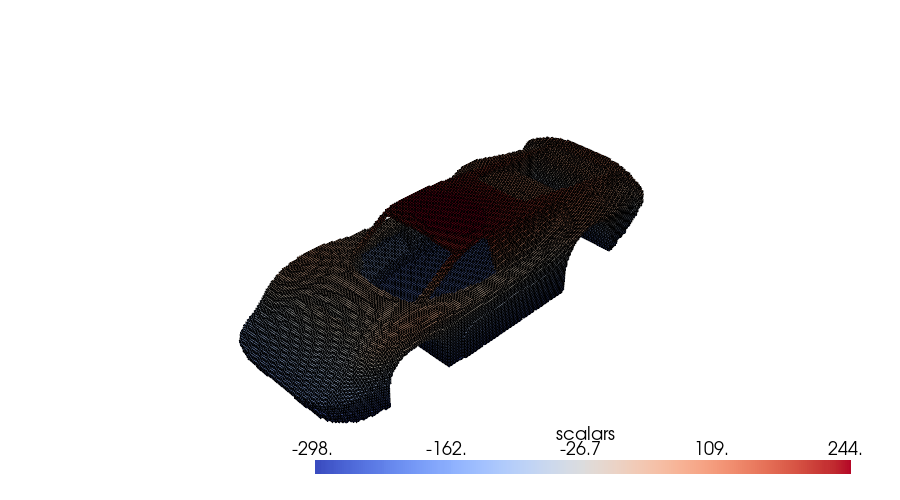

In [3]:
pv_obj = PolyData(
    PointData(coords=coords_H8, frame=frame),
    H8(topo=topo_H8, frames=frame),
).to_pv(multiblock=False, scalars=coords_H8[:, 2])[0]

plotter = pv.Plotter(notebook=True, window_size=(900, 500))
plotter.add_mesh(pv_obj, cmap="coolwarm", show_edges=True)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

## Aerodynamic drag as concentrated nodal forces

The GT40's top speed at Le Mans was around 330 km/h. From the voxel model we can estimate the total aerodynamic drag force using the standard drag equation:

$$F_d = \frac{1}{2}\, \rho\, v^2\, C_d\, A$$

where
- $\rho = 1.225\;\text{kg/m}^3$ (air density at sea level),
- $v = 330\;\text{km/h}$,
- $C_d \approx 0.35$ (historical drag coefficient for the GT40),
- $A$ is the frontal area (width × height of the bounding box, converted from mm to m).

The total drag is then distributed equally as point loads in the X direction to all nodes that lie on the front face of the voxel shell — the first layer of nodes at minimum X, within half a cell width of the front boundary.

The complete force vector (Fx, Fy, Fz) for every mesh node is stored as the field `"forces"` inside `PointData`, so it travels with the mesh wherever it goes.

In [4]:
# --- aerodynamic parameters -------------------------------------------------
rho = 1.225          # kg/m³
v   = 330 / 3.6     # m/s
Cd  = 0.35
mm_to_m = 1e-3

frontal_area_m2 = (size[1] * mm_to_m) * (size[2] * mm_to_m)
total_drag_N    = 0.5 * rho * v**2 * Cd * frontal_area_m2

print(f"Frontal area  : {frontal_area_m2:.4f} m²")
print(f"Total drag    : {total_drag_N:,.1f} N  ({total_drag_N/1e3:.2f} kN)")

# --- front-face nodes -------------------------------------------------------
x = coords_H8[:, 0]
x_min     = x.min()
half_cell = 0.5 * voxel_size[0]
front_ids = np.where(x < x_min + half_cell)[0]

force_per_node = total_drag_N / len(front_ids)
print(f"Front nodes   : {len(front_ids):,}")
print(f"Force per node: {force_per_node:.4f} N")

# --- build force array and attach to PointData ------------------------------
forces = np.zeros((coords_H8.shape[0], 3))
forces[front_ids, 0] = force_per_node   # Fx = drag direction (along car length)

pd = PointData(coords=coords_H8, frame=frame)
pd["forces"] = forces
cd = H8(topo=topo_H8, frames=frame)
model = PolyData(pd, cd)

print(f"\nForce field shape : {pd['forces'].to_numpy().shape}")
print(f"Loaded nodes      : {(forces[:, 0] != 0).sum():,}")
print(f"Sum Fx            : {forces[:, 0].sum():,.1f} N  (should match total drag)")

Frontal area  : 0.5373 m²
Total drag    : 967.9 N  (0.97 kN)
Front nodes   : 4,131
Force per node: 0.2343 N

Force field shape : (912951, 3)
Loaded nodes      : 4,131
Sum Fx            : 967.9 N  (should match total drag)


## Visualise the load distribution

Coloring each node by the magnitude of its applied force makes the loaded front-face stand out immediately against the unloaded shell.

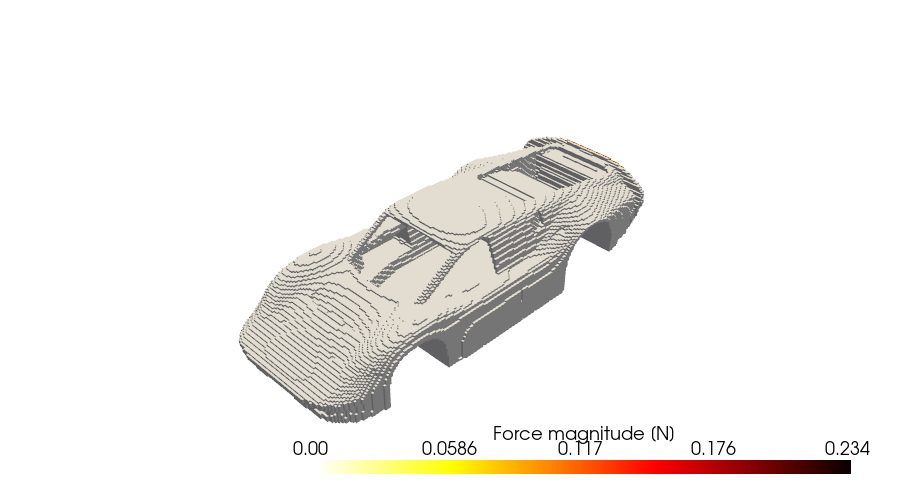

In [5]:
force_mag = np.linalg.norm(forces, axis=1)

pv_model = model.to_pv(multiblock=False, scalars=force_mag)[0]

plotter = pv.Plotter(notebook=True, window_size=(900, 500))
plotter.add_mesh(
    pv_model,
    cmap="hot_r",
    show_edges=False,
    scalar_bar_args={"title": "Force magnitude [N]"},
)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

### Force arrows

Scalar color alone doesn't show direction. PyVista's `glyph` method turns the stored force vectors into arrows: each loaded node gets an arrow whose orientation matches `(Fx, Fy, Fz)` and whose length is proportional to the force magnitude. Here all arrows point in the positive X direction (drag) and are equal in length, so the pattern traces the frontal silhouette of the car. The voxel shell is drawn translucent so the arrows are easy to read.

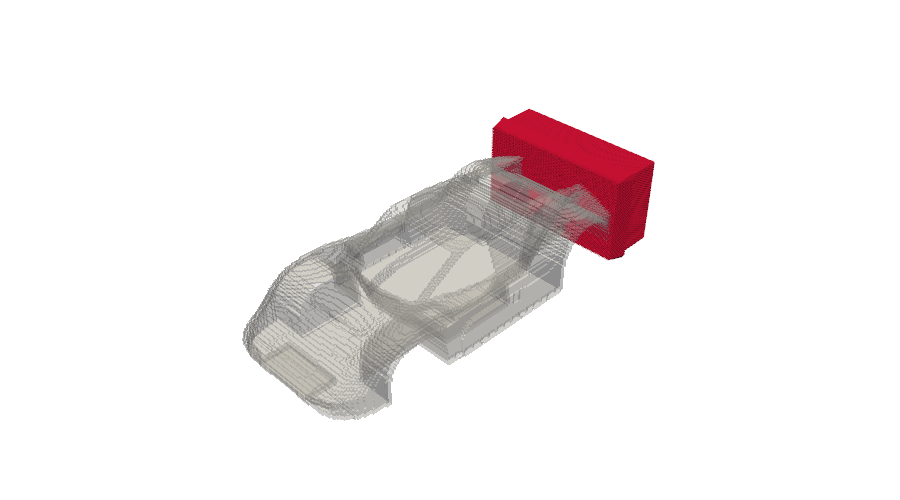

In [6]:
# point cloud of loaded nodes with force vectors attached
loaded_pts = pv.PolyData(coords_H8[front_ids])
loaded_pts["forces"] = forces[front_ids]

# scale so each arrow is ~15 % of the car's length
arrow_length_mm = 0.15 * size[0]
scale_factor    = arrow_length_mm / np.linalg.norm(forces[front_ids[0]])
arrows = loaded_pts.glyph(orient="forces", scale="forces", factor=scale_factor)

pv_shell = PolyData(
    PointData(coords=coords_H8, frame=frame),
    H8(topo=topo_H8, frames=frame),
).to_pv(multiblock=False)[0]

plotter = pv.Plotter(notebook=True, window_size=(900, 500))
plotter.add_mesh(pv_shell, color="lightgray", opacity=0.25, show_edges=False)
plotter.add_mesh(arrows, color="crimson", lighting=True)
plotter.camera_position = "iso"
plotter.show(jupyter_backend="static")

## Saving and reloading via Parquet

A voxel model with tens of thousands of cells and a full nodal load vector is the kind of data you want to checkpoint once and reload quickly for subsequent analysis. `PointData` and `H8` both expose `to_parquet` / `from_parquet` backed by Awkward Array's Parquet writer, which serialises the Awkward record structure — including named fields like `"forces"` — losslessly.

The pattern is:
- **Save**: one file for nodal data (`pd.to_parquet`), one for cell data (`cd.to_parquet`).
- **Reload**: `PointData.from_parquet` + `H8.from_parquet`, then re-wrap in `PolyData`.

In [7]:
pd.to_parquet("gt40_hires_pd.parquet")
cd.to_parquet("gt40_hires_cd.parquet")

import os
for fname in ["gt40_hires_pd.parquet", "gt40_hires_cd.parquet"]:
    size_mb = os.path.getsize(fname) / 1024**2
    print(f"{fname}  →  {size_mb:.2f} MB")

gt40_hires_pd.parquet  →  1.15 MB
gt40_hires_cd.parquet  →  1.22 MB


In [8]:
pd2 = PointData.from_parquet("gt40_hires_pd.parquet")
cd2 = H8.from_parquet("gt40_hires_cd.parquet")
model2 = PolyData(pd2, cd2)

forces2 = pd2["forces"].to_numpy()
print(f"Reloaded nodes      : {forces2.shape[0]:,}")
print(f"Loaded nodes        : {(forces2[:, 0] != 0).sum():,}")
print(f"Max Fx (reloaded)   : {forces2[:, 0].max():.6f} N")
print(f"Max Fx (original)   : {force_per_node:.6f} N")
print(f"Round-trip exact    : {np.allclose(forces, forces2)}")

Reloaded nodes      : 912,951
Loaded nodes        : 4,131
Max Fx (reloaded)   : 0.234303 N
Max Fx (original)   : 0.234303 N
Round-trip exact    : True


In [9]:
import os

for fname in ["gt40_hires_pd.parquet", "gt40_hires_cd.parquet"]:
    if os.path.exists(fname):
        os.remove(fname)

## Takeaway

A surface scan of an arbitrarily complex shape can be turned into a structured hexahedral mesh in a single `voxelize_T3_H8` call, regardless of topology. At 220 × 80 × 50 the GT40 has enough spatial resolution that the voxel model is a meaningful — if coarse — starting point for structural or aerodynamic analysis.

Nodal data (here, a force vector) is a first-class citizen of `PointData`: assign any named NumPy array as a field and it travels with the mesh through plotting, parquet serialization, and back. The Parquet round-trip is exact to floating-point precision, so a model checkpointed to disk is bit-for-bit identical when reloaded.